# Mamba

A small, hands-on look at Mamba, a language model architecture that replaces attention with a state-space model (SSM).

The core idea: instead of looking back at every previous token (attention), Mamba carries a fixed-size hidden state that it updates one token at a time:

```
h_t = A_t * h_(t-1) + B_t * x_t      (update the memory)
y_t = C_t * h_t                      (read from the memory)
```

What makes it "selective" is that the update depends on the current input, so the model can choose what to remember and what to forget.

## Part 1: A toy selective state-space model
This model will show how Mamba works on the backend, and the pieces that typically make it up rather than just importing the model and watching it run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

N = 4                                        # size of the hidden state (real Mamba-130m uses 16 per channel)
A = -np.array([0.3, 1.0, 3.0, 10.0])         # negative numbers = memory decays; each slot decays at its own speed
B = rng.normal(size=N)                       # how an input gets written into the state
C = rng.normal(size=N)                       # how the state is read out

def softplus(z):
    return np.log1p(np.exp(z))

def toy_scan(x):
    h = np.zeros(N)                          # the hidden state
    ys, hs, deltas = [], [], []
    for x_t in x:
        delta = softplus(3.0 * abs(x_t) - 2.0)
        A_bar = np.exp(delta * A)            # how much of the old state survives this step
        B_bar = delta * B                    # how strongly the new input is written
        h = A_bar * h + B_bar * x_t          # update the memory (The state equation)
        ys.append(C @ h)                     # read from the memory (The output equation)
        hs.append(h.copy())
        deltas.append(delta)
    return np.array(ys), np.array(hs), np.array(deltas)

# A made-up "sentence": mostly quiet, with two important tokens (spikes) at t=20 and t=60.
L = 100
x = 0.05 * rng.normal(size=L)
x[20], x[60] = 2.0, -1.5

y, hs, deltas = toy_scan(x)
print("Input length:", L, "| hidden state shape at the end:", hs[-1].shape)

Input length: 100 | hidden state shape at the end: (4,)


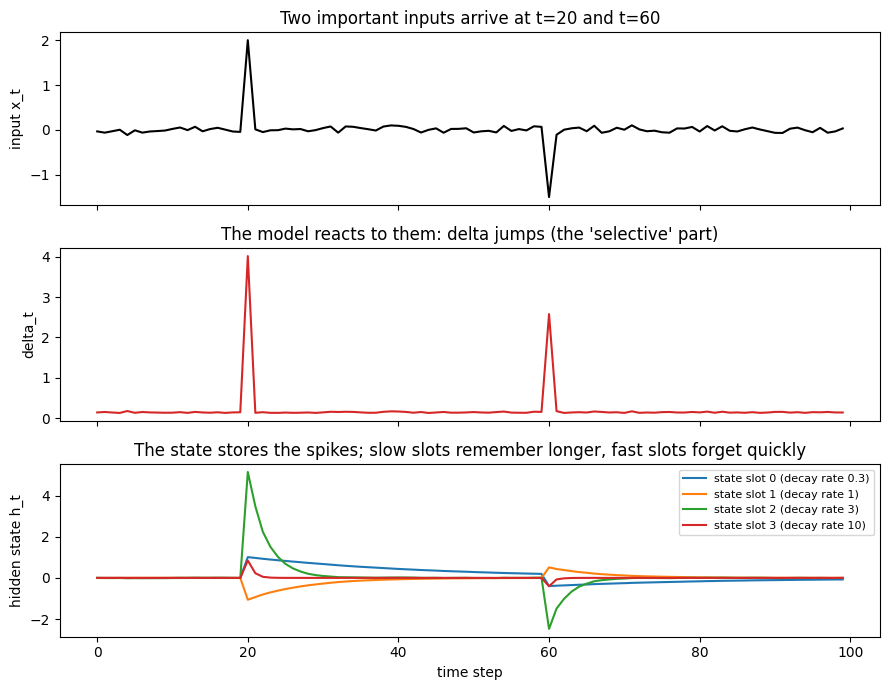

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)

axes[0].plot(x, color="black")
axes[0].set_ylabel("input x_t")
axes[0].set_title("Two important inputs arrive at t=20 and t=60")

axes[1].plot(deltas, color="tab:red")
axes[1].set_ylabel("delta_t")
axes[1].set_title("The model reacts to them: delta jumps (the 'selective' part)")

for i in range(N):
    axes[2].plot(hs[:, i], label=f"state slot {i} (decay rate {-A[i]:g})")
axes[2].set_ylabel("hidden state h_t")
axes[2].set_xlabel("time step")
axes[2].set_title("The state stores the spikes; slow slots remember longer, fast slots forget quickly")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

After each spike, the state holds a trace of it that fades over time, and slots with a smaller decay rate remember for longer. Nothing else is stored: the whole past is squeezed into N numbers.

That's why Mamba's memory doesn't grow with sequence length. Let's check by feeding in a sequence 100 times longer:

In [3]:
long_x = 0.05 * rng.normal(size=10_000)
_, long_hs, _ = toy_scan(long_x)
print(f"{len(long_x):,} inputs processed -> hidden state is still just {long_hs[-1].shape[0]} numbers")

10,000 inputs processed -> hidden state is still just 4 numbers


## Part 2: a real pretrained Mamba

Now the real thing: mamba-130m-hf, a 130M-parameter Mamba trained on the Pile.
It's small, so we can expect it to be fluent but not smart. Here, we can display the actual capabilities of Mamba and test the ideas described in the writeup.

In [4]:
import os
os.environ["USE_HUB_KERNELS"] = "0"   # keep Transformers from trying to download optional kernels

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "state-spaces/mamba-130m-hf"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id).to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Device: {device} | parameters: {n_params:,} | layers: {model.config.num_hidden_layers}")

config.json:   0%|          | 0.00/895 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  517MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

Device: cuda | parameters: 129,135,360 | layers: 24


### Generate some text

In [5]:
torch.manual_seed(0)

prompt = "The history of the printing press began when"
input_ids = tokenizer(prompt, return_tensors="pt")["input_ids"].to(device)

with torch.no_grad():
    output_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=60,
        do_sample=True,
        temperature=0.8,
        top_k=50,
        pad_token_id=tokenizer.eos_token_id,
    )

print(tokenizer.decode(output_ids[0], skip_special_tokens=True))

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `selective_scan_fn` is falling back to its reference PyTorch implementation because `mamba_ssm` is not installed. This is correct but much slower; install `mamba_ssm` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `selective_state_update` is falling back to its reference PyTorch implementation because `mamba_ssm` is not installed. This is correct but much slower; install `mamba_ssm` for the optimized kernel.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPTNeoXTokenizer. The clean_up_tokenization post-processing step is d

The history of the printing press began when Henry I of England made the first printed document in England, a document dated as far back as 1142. The invention, which became the basis of modern printing, came to be known as the printing press. The first printing press was brought to market in 1792 by the English author Thomas Browne


### What does the model "think" comes next?

Mamba reads the prompt token by token, updating its state, then outputs a probability for every word in its vocabulary. Here are its top guesses:

In [6]:
def top_next_tokens(prompt, k=5):
    ids = tokenizer(prompt, return_tensors="pt")["input_ids"].to(device)
    with torch.no_grad():
        logits = model(input_ids=ids).logits[0, -1]
    probs = F.softmax(logits.float(), dim=-1)
    top = torch.topk(probs, k)
    print(f'"{prompt}"')
    for p, i in zip(top.values, top.indices):
        print(f"   {tokenizer.decode(i)!r:<14} {p.item():6.1%}")
    print()

top_next_tokens("The capital of France is")
top_next_tokens("Two plus two equals")
top_next_tokens("Once upon a")

"The capital of France is"
   ' in'            8.0%
   ' the'           6.4%
   ' Paris'         5.2%
   ' a'             4.9%
   ' located'       3.6%

"Two plus two equals"
   ' four'         26.9%
   ' three'        16.0%
   ' five'          7.5%
   ' one'           7.2%
   ' two'           6.5%

"Once upon a"
   ' time'         96.7%
   ' long'          0.3%
   ' lifetime'      0.1%
   ' day'           0.1%
   '\n'             0.1%



### A look inside one Mamba layer

Mamba stacks identical blocks. Each block contains the pieces of the toy model from Part 1, just much bigger. Here is layer 0:

In [8]:
mixer = model.backbone.layers[0].mixer

for name, param in mixer.named_parameters():
    print(f"{name:<18} {tuple(param.shape)}")

A_log              (1536, 16)
D                  (1536,)
conv1d.weight      (1536, 1, 4)
conv1d.bias        (1536,)
in_proj.weight     (3072, 768)
x_proj.weight      (80, 1536)
dt_proj.weight     (1536, 48)
dt_proj.bias       (1536,)
out_proj.weight    (768, 1536)


Matching these to our toy model:

* A_log has shape (1536, 16): that's the decay rates A, one set of 16 state slots for each of 1536 channels (stored as logs so they stay positive).
* x_proj and dt_proj are the small layers that look at the input and produce B, C and delta. This is the "selective" part.
* in_proj / out_proj expand and shrink the data around the scan, and conv1d mixes in a few neighbouring tokens first.

So how much does the whole model remember, no matter how long the text is?

In [9]:
cfg = model.config
per_layer = cfg.intermediate_size * cfg.state_size
total = per_layer * cfg.num_hidden_layers
print(f"State per layer: {cfg.intermediate_size} channels x {cfg.state_size} slots = {per_layer:,} numbers")
print(f"Across {cfg.num_hidden_layers} layers: {total:,} numbers (about {total * 2 / 1024**2:.1f} MB in fp16)")
print("This stays the same whether the text is 10 tokens or 100,000 tokens long.")

State per layer: 1536 channels x 16 slots = 24,576 numbers
Across 24 layers: 589,824 numbers (about 1.1 MB in fp16)
This stays the same whether the text is 10 tokens or 100,000 tokens long.


## Takeaways

* Mamba processes text as a recurrence: read a token, update a fixed-size state, repeat.
* The update is input-dependent ("selective"), so the model can decide what to keep and what to overwrite.
* Because the state has a fixed size, memory use doesn't grow with context length, unlike attention, which keeps a key and value for every earlier token.

The ideas displayed here align exactly with what was described in the writeup about Mamba, how it works, and what it looks like inside.